# Análisis de redes: HITS, PageRank y PageRank sensible a tópico

**Minería de datos — Wikipedia, citas científicas y colaboraciones musicales**

Este trabajo compara tres formas de relevancia estructural usando PySpark local y el paradigma Map/Reduce. La unidad de análisis es un grafo por dataset; no se mezclan las redes.

**Alcance:** todos los artículos del espacio principal del dump de Wikipedia, el grafo completo de HepPh y todos los artistas de Spotify. El piloto de Wikipedia se usa exclusivamente para estimar recursos; sus resultados no sustituyen el análisis completo.

El notebook lee resultados persistidos y muestra su estado real. Una sección marcada **PENDIENTE** no es un resultado experimental. Para recalcular, activar `EJECUTAR_PIPELINE`; puede requerir muchas horas. Conservar este notebook junto a `src/`, `run.py` y los datos/resultados del proyecto.

## 1. Preguntas de investigación

1. ¿Qué nodos reciben mayor relevancia global según PageRank?
2. ¿Qué diferencias hay entre nodos que enlazan a buenas autoridades (hubs) y nodos enlazados por buenos hubs (autoridades)?
3. ¿Cómo cambia la clasificación cuando la teleportación favorece un tema?
4. ¿Qué coste tienen la extracción y las iteraciones, y qué limitaciones impone la construcción de cada grafo?

La centralidad mide posición en esta red, no calidad intrínseca, causalidad ni popularidad fuera del dataset.

## 2. Entorno reproducible

Python 3.11, Java 17 y PySpark 3.5.7. Las dependencias directas están en `requirements.txt` y todas las versiones instaladas en `requirements.lock.txt`.

Se reservan 10 GB para la JVM y cuatro trabajadores locales. Los procesos Python y el sistema operativo necesitan memoria adicional; 10 GB no representan el consumo total. Parquet almacena tablas intermedias; Spark puede derramar particiones a disco.

Desde una terminal del proyecto: `.venv/bin/python run.py all`. Para refrescar las salidas sin recalcular: `.venv/bin/python run.py report`.

In [1]:
import sys, json, platform, importlib.metadata
from pathlib import Path
from IPython.display import display, Markdown, Code
import pandas as pd
from src.data import ROOT
from src.report import show_dataset

EJECUTAR_PIPELINE = False  # True ejecuta las tres redes completas; no ejecutar en paralelo con run.py all.
display(pd.DataFrame([{'Python': platform.python_version(),
                       'PySpark': importlib.metadata.version('pyspark'),
                       'RAM del equipo (GB)': 24, 'Trabajadores locales': 4, 'JVM (GB)': 10}]))
print('Proyecto:', ROOT)


,Python,PySpark,RAM del equipo (GB),Trabajadores locales,JVM (GB)
0,3.11.18,3.5.7,24,4,10


Proyecto: /mnt/disk1/analisis-redes-pyspark


## 3. Datos, procedencia y definición de aristas

| Dataset | Nodo | Arista | Semillas temáticas |
|---|---|---|---|
| Wikipedia | Artículo canónico, namespace 0 | Enlace explícito del wikitext hacia otro artículo | Título y categorías |
| HepPh | Artículo científico | Artículo que cita → artículo citado | Títulos y resúmenes de arXiv |
| Spotify | Artista | Colaboración, recíproca cuando no hay dirección documentada | Géneros disponibles |

Se eliminan autoenlaces y duplicados, se conservan aislados y se usan pesos unitarios. Las redirecciones de Wikipedia se resuelven hasta alcanzar artículos canónicos; cadenas sin destino y ciclos quedan registrados. No se expanden plantillas: este grafo no equivale exactamente a todos los enlaces de las páginas renderizadas.

La descarga directa de Spotify redirigió a Google Storage y falló por validación TLS. Para esta ejecución se obtuvo una copia pública de los CSV originales desde [este repositorio](https://github.com/raquelanamb/spotify-feature-network). Sus tamaños coinciden con los publicados por la API oficial de Kaggle (9,980,131 y 13,817,766 bytes), y se registraron hashes SHA-256 locales. Esto no constituye verificación contra un checksum oficial. Se conservaron seis artistas presentes solo en las aristas, con metadatos vacíos.

El archivo de Wikipedia es **`enwiki-latest-pages-articles-multistream.xml.bz2`**. Se lee incrementalmente, sin descomprimirlo completo en disco. Cada manifiesto registra fecha, tamaño y SHA-256; `latest` no se interpreta como una versión fija.

HepPh publica 34,546 nodos y 421,578 aristas antes de la limpieza. En Spotify se comprueba el esquema antes de procesar; no se asumen géneros inexistentes.

In [2]:
manifests = []
for p in (ROOT/'data/raw').rglob('*.csv.json'):
    obj = json.loads(p.read_text())
    manifests.append({k: obj.get(k) for k in ['url', 'bytes', 'sha256', 'observed_at']})
for p in (ROOT/'data/raw').glob('*.json'):
    obj = json.loads(p.read_text())
    if 'sha256' in obj:
        manifests.append({k: obj.get(k) for k in ['url', 'bytes', 'sha256', 'observed_at']})
display(pd.DataFrame(manifests))


""


### Piloto y viabilidad

El piloto recorre las primeras 1,000 páginas. Su extrapolación divide el tamaño del dump entre los bytes comprimidos consumidos; las lecturas anticipadas del descompresor y el orden de las páginas introducen incertidumbre. Se reserva un factor de ocho sobre el Parquet proyectado para otras representaciones y temporales, más descarga y 20 GiB de margen. Esta regla es una estimación de planificación, no una cota formal.

Si la estimación excede el espacio libre, el pipeline se detiene antes de descargar el archivo completo. La extracción también se detiene si quedan menos de 15 GiB. Una muestra nunca se etiqueta como Wikipedia completa.

In [3]:
pilot_path = ROOT/'results/wiki_pilot.json'
if pilot_path.exists():
    pilot = json.loads(pilot_path.read_text())
    display(pd.DataFrame([{
        'Páginas piloto': pilot['pages_scanned'],
        'Tiempo piloto (s)': pilot['seconds'],
        'Extracción completa estimada (h)': pilot['projected_seconds']/3600,
        'Disco pico estimado (GiB)': pilot['estimated_peak_disk_bytes']/2**30,
        'Disco libre al medir (GiB)': pilot['free_bytes']/2**30,
        'Cabe según estimación': pilot['disk_ok']}]))
else:
    print('Piloto pendiente: ejecutar .venv/bin/python run.py pilot')


Piloto pendiente: ejecutar .venv/bin/python run.py pilot


## 4. Métodos y Map/Reduce

Sea $A_{ij}=1$ cuando existe una arista $i\to j$, y $d_i$ su grado de salida.

### PageRank

$$r^{(t+1)}_j=(1-\alpha)p_j+\alpha\sum_{i\to j}\frac{r_i^{(t)}}{d_i}+\alpha D^{(t)}p_j,$$

donde $D^{(t)}=\sum_{i:d_i=0}r_i^{(t)}$, $\alpha=0.85$ y $p_j=1/N$ en el caso uniforme.

**Map:** cada arista emite una contribución para su destino. **Reduce:** `reduceByKey` suma las contribuciones. Un `leftOuterJoin` mantiene también los nodos sin entradas. La masa de nodos sin salidas se redistribuye mediante el mismo vector de teleportación.

### HITS

$$a^{(t+1)}=A^T h^{(t)},\qquad h^{(t+1)}=A a^{(t+1)}.$$

Se normaliza cada vector con su norma L2 después de actualizarlo. Cada multiplicación se implementa como contribuciones por arista y suma por nodo; no se construye una matriz densa. La implementación es HITS global sobre el grafo suministrado, no una búsqueda web que construya un conjunto base por consulta.

En un grafo simétrico, hubs y autoridades pueden coincidir; en componentes o valores singulares dominantes degenerados, las soluciones pueden no ser únicas. No se interpreta la coincidencia como un error.

### PageRank sensible a tópico

Para un conjunto de semillas $S_k$, se usa $p^{(k)}_j=1/|S_k|$ si $j\in S_k$ y cero en otro caso. Se precalcula un ranking por tópico y se muestra la mezcla equiponderada $r_{mix}=\frac{1}{K}\sum_k r^{(k)}$. Esto permite estudiar relevancia temática manteniendo el grafo completo.

Los conjuntos pueden solaparse. No se inventan semillas cuando falta información; los nodos sin metadatos permanecen en el grafo y pueden recibir puntuación a través de enlaces.

### Convergencia y almacenamiento

Tolerancia global L1 `1e-8`, máximo 200 iteraciones. En HITS se usa el máximo de los cambios L1 de ambos vectores. Llegar al máximo no significa haber convergido. Se guardan residuales y tiempos, se persisten las aristas y se libera el estado anterior. Los checkpoints periódicos cortan el linaje de Spark; los resultados terminados permiten reanudar por algoritmo. Una iteración interrumpida se recalcula al reiniciar ese algoritmo.

In [4]:
from src.graphs import TOPICS
display(pd.DataFrame([{'dataset': d, 'tópico': t, 'expresión regular': rule}
                      for d, topics in TOPICS.items() for t, rule in topics.items()]))


,dataset,tópico,expresión regular
0,wikipedia,ciencia,(?i)\b(science|scientific|physics|chemistry|bi...
1,wikipedia,musica,(?i)\b(music|musical|musician|album|song|singe...
2,wikipedia,deportes,(?i)\b(sport|sports|football|basketball|olympi...
3,hepph,neutrinos,(?i)\bneutrinos?\b
4,hepph,higgs,(?i)\bhiggs\b
5,hepph,supersimetria,(?i)\b(supersymmetr\w*|susy|supergravity)\b
6,spotify,rock,(?i)\brock\b
7,spotify,pop,(?i)\bpop\b
8,spotify,hiphop,(?i)\b(hip[ -]?hop|rap)\b


### Implementación inspeccionable

Las siguientes funciones son las utilizadas por el pipeline. Se muestran dentro del notebook para conectar las ecuaciones con las operaciones distribuidas.

In [5]:
import inspect
from src.ranking import pagerank, hits
display(Code(inspect.getsource(pagerank), language='python'))
display(Code(inspect.getsource(hits), language='python'))


def pagerank(nodes, edges, personalization=None, alpha=.85, tol=1e-8,
             max_iter=200, checkpoint_every=10, on_iteration=None):
    n = nodes.count()
    if not n:
        raise ValueError('Grafo vacío')
    partitions = edges.getNumPartitions()
    base = nodes.map(lambda x: (x, 0.0)).partitionBy(partitions)
    if personalization is None:
        p = base.mapValues(lambda _: 1/n)
    else:
        mass = personalization.values().sum()
        if mass <= 0 or personalization.filter(lambda x: x[1] < 0).take(1):
            raise ValueError('Personalización inválida o sin semillas')
        if personalization.keys().subtract(nodes).take(1):
            raise ValueError('Semilla fuera del grafo')
        p = base.leftOuterJoin(personalization, numPartitions=partitions).mapValues(lambda v: (v[1] or 0)/mass)
    p = p.persist(StorageLevel.MEMORY_AND_DISK)
    degree = edges.mapValues(lambda _: 1).reduceByKey(add, numPartitions=partitions)
    transitions = edges.join(degree, numPartitions=partitions).mapValues(lambda v: (v[0], v[1])).persist(StorageLevel.MEMORY_AND_DISK)
    dangling = base.subtractByKey(degree).persist(StorageLevel.MEMORY_AND_DISK)
    ranks = p.mapValues(float).persist(StorageLevel.MEMORY_AND_DISK)
    history = []
    started = time.perf_counter()
    for iteration in range(1, max_iter+1):
        dm = dangling.join(ranks, numPartitions=partitions).values().map(lambda v: v[1]).sum()
        # Map: repartir rango por arista. Reduce: sumar por destino.
        incoming = transitions.join(ranks, numPartitions=partitions).map(lambda kv: (kv[1][0][0], kv[1][1]/kv[1][0][1])).reduceByKey(add, numPartitions=partitions)
        nxt = p.leftOuterJoin(incoming, numPartitions=partitions).mapValues(lambda v: (1-alpha+alpha*dm)*v[0]+alpha*(v[1] or 0.0)).persist(StorageLevel.MEMORY_AND_DISK)
        if iteration % checkpoint_every == 0:
            nxt.checkpoint()
            nxt.count()  # Materializar el checkpoint del RDD, no solo un descendiente.
        residual = ranks.join(nxt, numPartitions=partitions).values().map(lambda v: abs(v[0]-v[1])).sum()
        history.append(dict(iteration=iteration, residual=residual, seconds=time.perf_counter()-started, **resource_sample()))
        if on_iteration:
            on_iteration(history[-1])
        ranks.unpersist()
        ranks = nxt
        if residual < tol:
            break
    transitions.unpersist(); dangling.unpersist(); p.unpersist()
    return ranks, history

def hits(nodes, edges, tol=1e-8, max_iter=200, checkpoint_every=10, on_iteration=None,
         initial_a=None, initial_h=None, start_iter=1, history_init=None, on_checkpoint=None):
    n = nodes.count()
    if not n:
        raise ValueError('Grafo vacío')
    partitions = edges.getNumPartitions()
    base = nodes.map(lambda x: (x, 0.0)).partitionBy(partitions).persist(StorageLevel.MEMORY_AND_DISK)
    reverse = edges.map(lambda e: (e[1], e[0])).persist(StorageLevel.MEMORY_AND_DISK)
    if initial_h is not None and initial_a is not None:
        h = initial_h
        a = initial_a
    else:
        h = base.mapValues(lambda _: 1/math.sqrt(n)).persist(StorageLevel.MEMORY_AND_DISK)
        a = h.mapValues(float).persist(StorageLevel.MEMORY_AND_DISK)
    history = list(history_init) if history_init else []
    started = time.perf_counter()

    def update(links, scores):
        raw = links.join(scores, numPartitions=partitions).map(lambda kv: (kv[1][0], kv[1][1])).reduceByKey(add, numPartitions=partitions).persist(StorageLevel.MEMORY_AND_DISK)
        norm = math.sqrt(raw.values().map(lambda x: x*x).sum())
        out = base.leftOuterJoin(raw, numPartitions=partitions).mapValues(lambda v: (v[1] or 0.0)/norm if norm else 0.0).persist(StorageLevel.MEMORY_AND_DISK)
        out.count(); raw.unpersist()
        return out

    for iteration in range(start_iter, max_iter+1):
        na = update(edges, h)
        nh = update(reverse, na)
        if iteration % checkpoint_every == 0:
            na.checkpoint(); nh.checkpoint()
            na.count(); nh.count()
        residual = max(a.join(na, numPartitions=partitions).values().map(lambda v: abs(v[0]-v[1])).sum(), h.join(nh, numPartitions=partitions).values().map(lambda v: abs(v[0]-v[1])).sum())
        history.append(dict(iteration=iteration, residual=residual, seconds=time.perf_counter()-started, **resource_sample()))
        if on_iteration:
            on_iteration(history[-1])
        a.unpersist(); h.unpersist()
        a, h = na, nh
        if on_checkpoint and iteration % checkpoint_every == 0:
            on_checkpoint(iteration, a, h, history)
        if residual < tol:
            break
    base.unpersist(); reverse.unpersist()
    return a, h, history

## 5. Ejecución reanudable

La ejecución se organiza por etapas: adquisición → metadatos/extracción → construcción → algoritmos → tablas. Los módulos `src/data.py`, `src/graphs.py` y `src/pipeline.py` contienen estas etapas.

Los archivos originales quedan en `data/raw`, las tablas en `data/processed` y los resultados en `results`. No se recogen grafos completos en Pandas; solo tablas pequeñas y distribuciones agregadas. No iniciar dos ejecuciones sobre la misma carpeta de resultados.

In [6]:
if EJECUTAR_PIPELINE:
    import subprocess
    subprocess.run([sys.executable, 'run.py', 'all'], cwd=ROOT, check=True)
else:
    print('Modo informe: se muestran resultados guardados. No se recalculan datasets.')


Modo informe: se muestran resultados guardados. No se recalculan datasets.


## 6. Validación

Se comparan PageRank uniforme y personalizado con NetworkX en grafos pequeños que incluyen aislados, nodos sin salidas y componentes desconectados. HITS se contrasta con NetworkX tras igualar la normalización. Se prueban además lectura XML, enlaces repetidos, fragmentos, cadenas de redirecciones, ciclos y reanudación de extracción.

Para cada ranking real se comprueba cobertura de nodos, puntuaciones finitas y no negativas, y suma unitaria para PageRank. NetworkX se utiliza como referencia de prueba, no como motor de Wikipedia.

In [7]:
test_log = ROOT/'results/tests.log'
if test_log.exists():
    print(test_log.read_text()[-5000:] or 'Pruebas en curso; todavía no hay resultado final.')
else:
    print('Validación pendiente: .venv/bin/python -m pytest -q tests')


============================= test session starts ==============================
platform linux -- Python 3.11.18, pytest-8.3.4, pluggy-1.7.0
rootdir: /mnt/disk1/analisis-redes-pyspark
configfile: pytest.ini
plugins: platformdirs-4.13.5
collecting ... 
collected 8 items                                                              

tests/test_algorithms.py ....                                            [ 50%]
tests/test_download_resume.py ..                                         [ 75%]
tests/test_extraction_resume.py .                                        [ 87%]
tests/test_pipeline.py .                                                 [100%]

=============================== warnings summary ===============================
tests/test_pipeline.py: 28 warnings
  /mnt/disk1/analisis-redes-pyspark/.venv/lib/python3.11/site-packages/pyspark/sql/pandas/utils.py:37: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
    if LooseVersion(pandas.__ver

## 7. HepPh: red de citas

Una autoridad recibe citas de buenos hubs. Un hub puede ser un artículo de revisión o uno con referencias a trabajos centrales; no se puede inferir su tipo sin inspeccionar el contenido. La personalización distingue temas de física dentro de la misma red.

,directed,metadata_count,metadata_coverage,nodes,raw_edges,edges
0,True,34544,0.999942,34546,421578,421534


,labels,all_topics,all_converged
0,"[pagerank, authority, hub, topic_neutrinos, to...",True,True


### authority

,id,score,title
0,9803315,0.409000,The Hierarchy Problem and New Dimensions at a ...
1,9804398,0.333022,New Dimensions at a Millimeter to a Fermi and ...
2,9807344,0.287051,"Phenomenology, Astrophysics and Cosmology of T..."
3,9811291,0.195909,Quantum Gravity and Extra Dimensions at High-E...
4,9905221,0.188321,A Large Mass Hierarchy from a Small Extra Dime...
5,9811350,0.180304,On Kaluza-Klein States from Large Extra Dimens...
6,9803466,0.172975,Extra Spacetime Dimensions and Unification
7,9811337,0.168654,Collider Signatures of New Large Space Dimensions
8,9806292,0.159061,Grand Unification at Intermediate Mass Scales ...
9,9811356,0.156665,Indirect Collider Signals for Extra Dimensions


### hub

...

,id,score,title
0,9206203,0.005694,Constraints From Gauge Coupling Unification On...
1,9206242,0.004352,$SU(3)\otimes U(1)$ Model for Electroweak Inte...
2,9207213,0.003669,Implication of Combined Solar Neutrino Observa...
3,9303230,0.003516,Dynamical Supersymmetry Breaking at Low Energies
4,9205227,0.003215,"Supersymmetry, Naturalness, and Dynamical Supe..."
5,9211266,0.003192,Soft SUSY Breaking Terms in Stringy Scenarios:...
6,9203220,0.003149,Test of the Dimopouos-Hall-Raby Ansatz for Fer...
7,9209232,0.002748,Supersymmetric Grand Unified Theories: Two Loo...
8,9206205,0.002524,Flavor changing interactions mediated by scala...
9,9207219,0.002381,Troubles with the Minimal SU(5) Supergravity M...


### topic_neutrinos

,id,score,title
0,9206242,0.010038,$SU(3)\otimes U(1)$ Model for Electroweak Inte...
1,9207213,0.009728,Implication of Combined Solar Neutrino Observa...
2,9203213,0.006335,Solar Neutrino Data and Its Implications
3,9306212,0.006130,Astrophysical Solutions are Incompatible with ...
4,9212204,0.005806,Do Solar Neutrino Experiments Imply New Physics?
5,9311214,0.005448,"Solar Model Uncertainties, MSW Analysis, and F..."
6,9807216,0.004558,Where do we stand with solar neutrino oscillat...
7,9311306,0.004011,New Constraints on Neutrino Oscillations in Va...
8,9505425,0.003895,Solar Models with Helium and Heavy Element Dif...
9,9503439,0.003398,Calculation of the Flux of Atmospheric Neutrinos


### topic_supersimetria

,id,score,title
0,9206203,0.009775,Constraints From Gauge Coupling Unification On...
1,9303230,0.007328,Dynamical Supersymmetry Breaking at Low Energies
2,9205227,0.006664,"Supersymmetry, Naturalness, and Dynamical Supe..."
3,9211266,0.005709,Soft SUSY Breaking Terms in Stringy Scenarios:...
4,9203220,0.004550,Test of the Dimopouos-Hall-Raby Ansatz for Fer...
5,9209232,0.004252,Supersymmetric Grand Unified Theories: Two Loo...
6,9207219,0.004192,Troubles with the Minimal SU(5) Supergravity M...
7,9210235,0.004027,Uncertainties in Coupling Constant Unification
8,9207234,0.003555,The Neutralino Relic Density in Minimal N=1 Su...
9,9408384,0.003461,Dynamical Supersymmetry Breaking Simplified


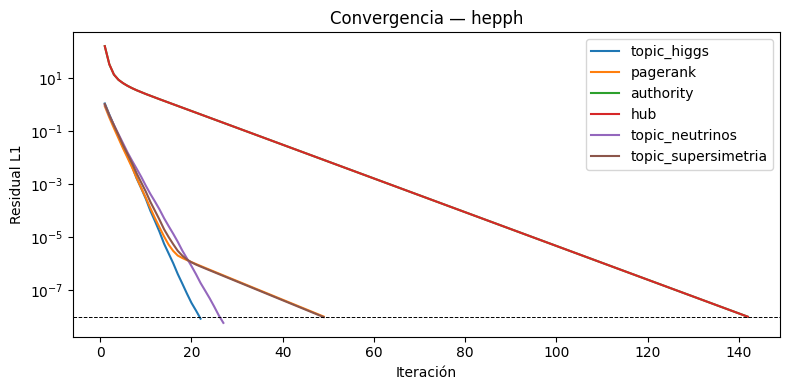

,algoritmo,iteraciones,segundos,convergio,rss_muestreado_max_GiB
0,topic_higgs,22,29.378231,True,2.126389
1,pagerank,49,63.450121,True,2.882019
2,authority,142,418.348646,True,2.125732
3,hub,142,418.348646,True,2.125732
4,topic_neutrinos,27,35.520027,True,2.123352
5,topic_supersimetria,49,64.380684,True,2.127365


### Comparación: correlación de puntuaciones y coincidencia del top 20

,a,b,pearson_scores,top20_overlap
0,pagerank,authority,0.276318,0.05
1,pagerank,hub,-0.016975,0.00
2,pagerank,topic_neutrinos,0.443969,0.10
3,pagerank,topic_higgs,0.591324,0.30
4,pagerank,topic_supersimetria,0.552301,0.20
5,pagerank,topic_mixture,0.666225,0.45
6,authority,hub,0.316254,0.05
7,authority,topic_neutrinos,0.172674,0.00
8,authority,topic_higgs,0.312615,0.05
9,authority,topic_supersimetria,0.284999,0.00


**Interpretación de los resultados obtenidos.** PageRank coloca primero a **CTEQ Parton Distributions and Flavor Dependence of Sea Quarks**; HITS identifica a **The Hierarchy Problem and New Dimensions at a Millimeter** como primera autoridad y a **Testing the Nature of Kaluza-Klein Excitations at Future Lepton Colliders** como primer hub. PageRank y autoridades comparten 1 de los primeros 20 nodos y su correlación de puntuaciones es 0.276. Las clasificaciones reflejan criterios estructurales distintos; no son medidas intercambiables de calidad.

### Cobertura temática y reglas

...

,id,title,topic_rank,pagerank_rank,gain
0,9206203,Constraints From Gauge Coupling Unification On...,1,4,3
1,9203203,Towards the Theory of Cosmological Phase Trans...,2,8,6
2,9206205,Flavor changing interactions mediated by scala...,3,18,15
3,9307201,The Renormalization-Group Improved Higgs Secto...,4,100,96
4,9205238,Radiative Correction Effects of a Very Heavy Top,5,19,14
5,9210266,Radiative corrections to the decay H==>hh in t...,6,120,114
6,9203223,Testing the Higgs Sector of the Minimal Supers...,7,114,107
7,9212305,Upper Bounds on the Lightest Higgs Boson Mass ...,8,154,146
8,9803315,The Hierarchy Problem and New Dimensions at a ...,9,7,-2
9,9401219,Two-Loop Radiative Corrections to the Lightest...,10,183,173


### Cambio de posición: changes_topic_neutrinos

,id,title,topic_rank,pagerank_rank,gain
0,9206242,$SU(3)\otimes U(1)$ Model for Electroweak Inte...,1,6,5
1,9207213,Implication of Combined Solar Neutrino Observa...,2,15,13
2,9203213,Solar Neutrino Data and Its Implications,3,41,38
3,9306212,Astrophysical Solutions are Incompatible with ...,4,47,43
4,9212204,Do Solar Neutrino Experiments Imply New Physics?,5,55,50
5,9311214,"Solar Model Uncertainties, MSW Analysis, and F...",6,62,56
6,9807216,Where do we stand with solar neutrino oscillat...,7,87,80
7,9311306,New Constraints on Neutrino Oscillations in Va...,8,109,101
8,9505425,Solar Models with Helium and Heavy Element Dif...,9,118,109
9,9503439,Calculation of the Flux of Atmospheric Neutrinos,10,143,133


### Cambio de posición: changes_topic_supersimetria

,id,title,topic_rank,pagerank_rank,gain
0,9206203,Constraints From Gauge Coupling Unification On...,1,4,3
1,9303230,Dynamical Supersymmetry Breaking at Low Energies,2,9,7
2,9205227,"Supersymmetry, Naturalness, and Dynamical Supe...",3,14,11
3,9211266,Soft SUSY Breaking Terms in Stringy Scenarios:...,4,17,13
4,9203220,Test of the Dimopouos-Hall-Raby Ansatz for Fer...,5,24,19
5,9209232,Supersymmetric Grand Unified Theories: Two Loo...,6,33,27
6,9207219,Troubles with the Minimal SU(5) Supergravity M...,7,45,38
7,9210235,Uncertainties in Coupling Constant Unification,8,36,28
8,9207234,The Neutralino Relic Density in Minimal N=1 Su...,9,39,30
9,9408384,Dynamical Supersymmetry Breaking Simplified,10,76,66


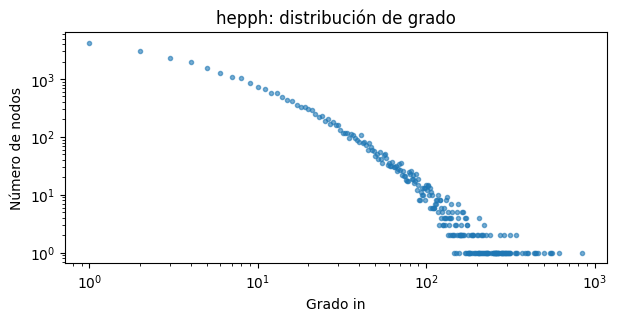

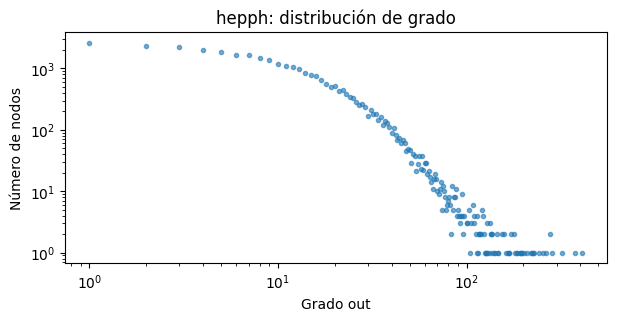

In [8]:
show_dataset('hepph')

## 7. Spotify: colaboraciones

La centralidad refleja conexiones entre colaboradores del dataset, no reproducciones ni popularidad comercial. En la representación recíproca hay que comparar explícitamente la similitud entre hubs y autoridades.

,directed,genres_available,nodes_without_metadata,model,nodes,raw_edges,edges
0,False,True,6,colaboración recíproca sin pesos,156326,600772,600772


,labels,all_topics,all_converged
0,"[pagerank, authority, hub, topic_rock, topic_p...",True,True


### authority

,id,score,title
0,329e4yvIujISKGKz1BZZbO,0.128226,Farruko
1,6vXTefBL93Dj5IqAWq6OTv,0.114707,French Montana
2,13y7CgLHjMVRMDqxdx0Xdo,0.109492,Gucci Mane
3,7c0XG5cIJTrrAgEC3ULPiq,0.105854,Ty Dolla $ign
4,3EiLUeyEcA6fbRPSHkG5kb,0.103752,De La Ghetto
5,55Aa2cqylxrFIXC767Z865,0.102231,Lil Wayne
6,7bXgB6jMjp9ATFy66eO08Z,0.102208,Chris Brown
7,7hJcb9fa4alzcOq3EaNPoG,0.100208,Snoop Dogg
8,4SsVbpTthjScTS7U2hmr1X,0.099750,Arcangel
9,1vyhD5VmyZ7KMfW5gqLgo5,0.099437,J Balvin


### hub

...

,id,score,title
0,7hJcb9fa4alzcOq3EaNPoG,0.000691,Snoop Dogg
1,13y7CgLHjMVRMDqxdx0Xdo,0.000661,Gucci Mane
2,6UBA15slIuadJ8h2lPRPos,0.000580,Tech N9ne
3,4AA474G2hRfrHyGrfyDseO,0.000528,Mozzy
4,1k5aZWIOUbUfKcnMxtEivJ,0.000526,Jimmy Barnes
5,5fMUXHkw8R8eOP2RNVYEZX,0.000510,Diplo
6,1U5zgr455OGyIkLNXvDdrf,0.000509,Traditional
7,77AiFEVeAVj2ORpC85QVJs,0.000505,Steve Aoki
8,5VX8hxrcfJWwaTLiqGUHG3,0.000503,TobyMac
9,2o5jDhtHVPhrJdv3cEQ99Z,0.000470,Tiësto


### topic_pop

,id,score,title
0,01pSsqt7FLdq2SC6UqjER3,0.000808,Raimonds Pauls
1,2wDTo0nO2ZKJN7VUeGmuyg,0.000646,Renuka Panwar
2,1mYsTxnqsietFxj1OgoGbG,0.000610,A.R. Rahman
3,1U5zgr455OGyIkLNXvDdrf,0.000601,Traditional
4,1wRPtKGflJrBx9BmLsSwlU,0.000585,Pritam
5,6cEuCEZu7PAE9ZSzLLc2oQ,0.000567,R3HAB
6,77AiFEVeAVj2ORpC85QVJs,0.000553,Steve Aoki
7,2o5jDhtHVPhrJdv3cEQ99Z,0.000553,Tiësto
8,5fMUXHkw8R8eOP2RNVYEZX,0.000545,Diplo
9,0SfsnGyD8FpIN4U4WCkBZ5,0.000524,Armin van Buuren


### topic_rock

,id,score,title
0,1k5aZWIOUbUfKcnMxtEivJ,0.001354,Jimmy Barnes
1,1db5TWniHR7iqwXer7AiQ2,0.001141,Pappo
2,5VX8hxrcfJWwaTLiqGUHG3,0.001101,TobyMac
3,3SXDCIdqI1AR686ukKtKCq,0.001081,Bi-2
4,32vWCbZh0xZ4o9gkz4PsEU,0.001014,Dolly Parton
5,6kACVPfCOnqzgfEF5ryl0x,0.000945,Johnny Cash
6,0UZq6vAHrwGgctvxTzzxYm,0.000928,Tokyo Ska Paradise Orchestra
7,5xLSa7l4IV1gsQfhAMvl0U,0.000907,B.B. King
8,5Ayl2bJtN5mdCsxZoxs9n1,0.000878,Collie Buddz
9,7Lij2ZLJJQOfGojVR3Wmqa,0.000842,Anthony B


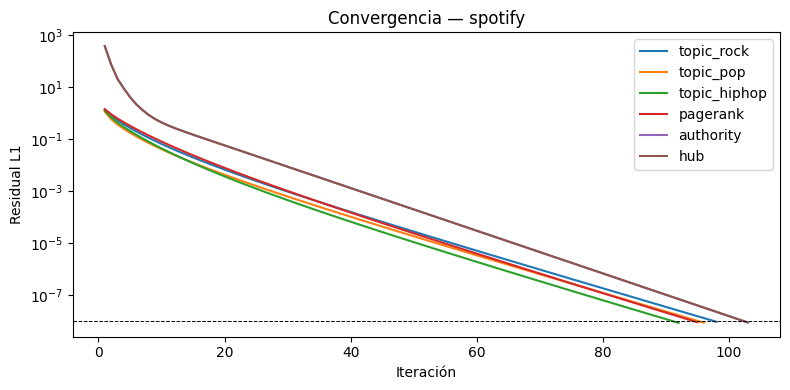

,algoritmo,iteraciones,segundos,convergio,rss_muestreado_max_GiB
0,topic_rock,98,171.477416,True,1.675003
1,topic_pop,96,162.746452,True,2.157745
2,topic_hiphop,92,160.496021,True,1.999817
3,pagerank,95,131.648973,True,NaN
4,authority,103,473.329807,True,1.726410
5,hub,103,473.329807,True,1.726410


### Comparación: correlación de puntuaciones y coincidencia del top 20

,a,b,pearson_scores,top20_overlap
0,pagerank,authority,0.320202,0.10
1,pagerank,hub,0.320202,0.10
2,pagerank,topic_rock,0.446804,0.05
3,pagerank,topic_pop,0.641857,0.50
4,pagerank,topic_hiphop,0.495852,0.10
5,pagerank,topic_mixture,0.639364,0.35
6,authority,hub,1.000000,1.00
7,authority,topic_rock,0.218585,0.00
8,authority,topic_pop,0.395979,0.10
9,authority,topic_hiphop,0.447616,0.20


**Interpretación de los resultados obtenidos.** PageRank coloca primero a **Johann Sebastian Bach**; HITS identifica a **Farruko** como primera autoridad y a **Farruko** como primer hub. PageRank y autoridades comparten 2 de los primeros 20 nodos y su correlación de puntuaciones es 0.320. Las clasificaciones reflejan criterios estructurales distintos; no son medidas intercambiables de calidad.

### Cobertura temática y reglas

...

,id,title,topic_rank,pagerank_rank,gain
0,4AA474G2hRfrHyGrfyDseO,Mozzy,1,29,28
1,13y7CgLHjMVRMDqxdx0Xdo,Gucci Mane,2,11,9
2,7hJcb9fa4alzcOq3EaNPoG,Snoop Dogg,3,12,9
3,6UBA15slIuadJ8h2lPRPos,Tech N9ne,4,69,65
4,56n1NeXsTOOxjX3Z4lVMTJ,SFDK,5,318,313
5,7GaMopkesD4KK9dNbgyO5D,Eko Fresh,6,53,47
6,6f4XkbvYlXMH0QgVRzW0sM,Waka Flocka Flame,7,23,16
7,0QcZD8V0Ug1KINWBSyG0dB,Alkpote,8,38,30
8,6trEYfLSuAd9CS8bCy4sOH,demxntia,9,352,343
9,7f35VZGDpomj11PXdNn5D9,Max B,10,50,40


### Cambio de posición: changes_topic_pop

,id,title,topic_rank,pagerank_rank,gain
0,01pSsqt7FLdq2SC6UqjER3,Raimonds Pauls,1,42,41
1,2wDTo0nO2ZKJN7VUeGmuyg,Renuka Panwar,2,26,24
2,1mYsTxnqsietFxj1OgoGbG,A.R. Rahman,3,8,5
3,1U5zgr455OGyIkLNXvDdrf,Traditional,4,2,-2
4,1wRPtKGflJrBx9BmLsSwlU,Pritam,5,21,16
5,6cEuCEZu7PAE9ZSzLLc2oQ,R3HAB,6,34,28
6,77AiFEVeAVj2ORpC85QVJs,Steve Aoki,7,18,11
7,2o5jDhtHVPhrJdv3cEQ99Z,Tiësto,8,19,11
8,5fMUXHkw8R8eOP2RNVYEZX,Diplo,9,20,11
9,0SfsnGyD8FpIN4U4WCkBZ5,Armin van Buuren,10,9,-1


### Cambio de posición: changes_topic_rock

,id,title,topic_rank,pagerank_rank,gain
0,1k5aZWIOUbUfKcnMxtEivJ,Jimmy Barnes,1,616,615
1,1db5TWniHR7iqwXer7AiQ2,Pappo,2,2071,2069
2,5VX8hxrcfJWwaTLiqGUHG3,TobyMac,3,387,384
3,3SXDCIdqI1AR686ukKtKCq,Bi-2,4,108,104
4,32vWCbZh0xZ4o9gkz4PsEU,Dolly Parton,5,427,422
5,6kACVPfCOnqzgfEF5ryl0x,Johnny Cash,6,998,992
6,0UZq6vAHrwGgctvxTzzxYm,Tokyo Ska Paradise Orchestra,7,237,230
7,5xLSa7l4IV1gsQfhAMvl0U,B.B. King,8,1294,1286
8,5Ayl2bJtN5mdCsxZoxs9n1,Collie Buddz,9,669,660
9,7Lij2ZLJJQOfGojVR3Wmqa,Anthony B,10,98,88


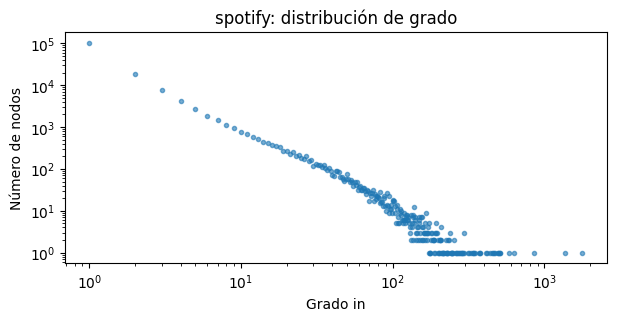

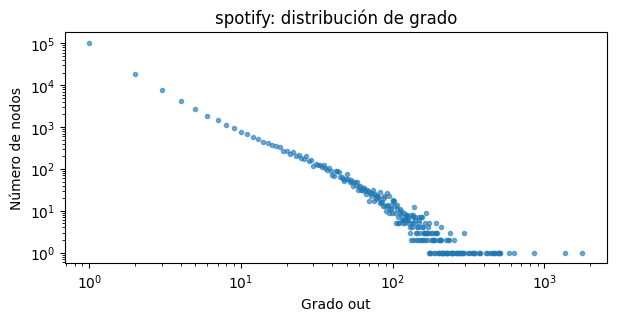

In [9]:
show_dataset('spotify')

## 7. Wikipedia: enlaces entre artículos

PageRank favorece artículos conectados desde páginas relevantes. Los hubs pueden ser listas o artículos con enlaces informativos. Un ranking temático favorece la región del grafo accesible desde sus semillas, con las limitaciones de las reglas léxicas.

,directed,redirects,resolved_redirects,unresolved_redirects_cycles_or_missing,unresolved_links,explicit_wikitext_links_only,nodes,raw_edges,edges
0,True,12065403,12037779,27624,17910254,True,7249099,242403921,235645261


,labels,all_topics,all_converged
0,"[pagerank, authority, hub, topic_ciencia, topi...",True,True


### authority

,id,score,title
0,30680,0.263377,The New York Times
1,3434750,0.226029,United States
2,32927,0.198797,World War II
3,645042,0.178695,New York City
4,18618239,0.148622,U.S. state
5,19344515,0.130067,The Guardian
6,57070,0.118713,United States Census Bureau
7,17867,0.118388,London
8,351656,0.117835,Geographic Names Information System
9,23962196,0.111249,2020 United States census


### hub

...

,id,score,title
0,10568,0.004347,Association football
1,548981,0.001076,Midfielder
2,649702,0.000895,Defender (association football)
3,428681,0.000795,Forward (association football)
4,3434750,0.000772,United States
5,32927,0.000736,World War II
6,3921,0.000707,Basketball
7,30680,0.000691,The New York Times
8,18951490,0.000631,American football
9,2403,0.000471,Australian rules football


### topic_mixture

,id,score,title
0,10568,0.001542,Association football
1,30680,0.001019,The New York Times
2,3434750,0.000909,United States
3,32927,0.000719,World War II
4,697535,0.000679,AllMusic
5,18309966,0.000619,Billboard (magazine)
6,645042,0.000617,New York City
7,19344515,0.000594,The Guardian
8,31717,0.000522,United Kingdom
9,17867,0.000493,London


### topic_musica

,id,score,title
0,697535,0.001931,AllMusic
1,18309966,0.001732,Billboard (magazine)
2,30680,0.001289,The New York Times
3,3434750,0.000953,United States
4,645042,0.000885,New York City
5,24624,0.000837,Pop music
6,19344515,0.000826,The Guardian
7,25423,0.000825,Rock music
8,3524766,0.000758,YouTube
9,528282,0.000707,Album


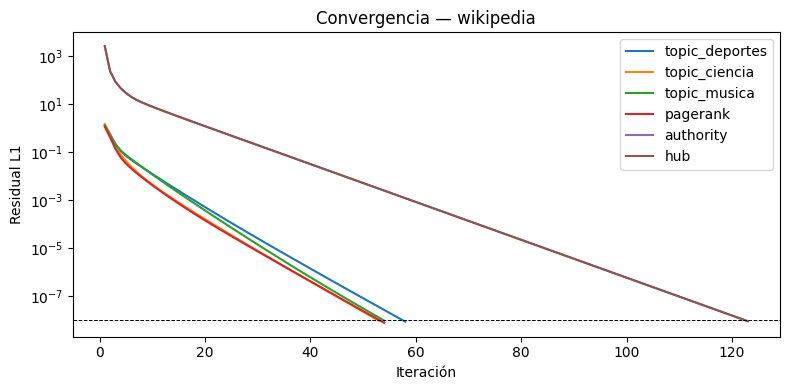

,algoritmo,iteraciones,segundos,convergio,rss_muestreado_max_GiB
0,topic_deportes,58,15065.124576,True,7.254761
1,topic_ciencia,53,14564.876022,True,6.371384
2,topic_musica,54,14624.526761,True,6.066303
3,pagerank,54,12431.715282,True,12.050049
4,authority,123,53429.439595,True,6.903000
5,hub,123,53429.439595,True,6.903000


### Comparación: correlación de puntuaciones y coincidencia del top 20

,a,b,pearson_scores,top20_overlap
0,pagerank,authority,0.836971,0.50
1,pagerank,hub,0.149907,0.05
2,pagerank,topic_ciencia,0.818237,0.55
3,pagerank,topic_musica,0.664153,0.35
4,pagerank,topic_deportes,0.661985,0.50
5,pagerank,topic_mixture,0.888483,0.65
6,authority,hub,0.173159,0.05
7,authority,topic_ciencia,0.656306,0.45
8,authority,topic_musica,0.701637,0.40
9,authority,topic_deportes,0.576454,0.45


**Interpretación de los resultados obtenidos.** PageRank coloca primero a **United States**; HITS identifica a **The New York Times** como primera autoridad y a **Demonym** como primer hub. PageRank y autoridades comparten 10 de los primeros 20 nodos y su correlación de puntuaciones es 0.837. Las clasificaciones reflejan criterios estructurales distintos; no son medidas intercambiables de calidad.

### Cobertura temática y reglas

...

,id,title,topic_rank,pagerank_rank,gain
0,30680,The New York Times,1,2,1
1,3434750,United States,2,1,-1
2,26787,Science fiction,3,767,764
3,32927,World War II,4,3,-1
4,324572,Academic journal,5,47,42
5,31717,United Kingdom,6,6,0
6,18831,Mathematics,7,154,147
7,645042,New York City,8,7,-1
8,24116,Peer review,9,91,82
9,19344515,The Guardian,10,8,-2


### Cambio de posición: changes_topic_deportes

,id,title,topic_rank,pagerank_rank,gain
0,10568,Association football,1,4,3
1,548981,Midfielder,2,111,109
2,649702,Defender (association football),3,163,160
3,428681,Forward (association football),4,194,190
4,3434750,United States,5,1,-4
5,32927,World War II,6,3,-3
6,3921,Basketball,7,118,111
7,30680,The New York Times,8,2,-6
8,18951490,American football,9,164,155
9,2403,Australian rules football,10,342,332


### Cambio de posición: changes_topic_musica

,id,title,topic_rank,pagerank_rank,gain
0,697535,AllMusic,1,58,57
1,18309966,Billboard (magazine),2,85,83
2,30680,The New York Times,3,2,-1
3,3434750,United States,4,1,-3
4,645042,New York City,5,7,2
5,24624,Pop music,6,316,310
6,19344515,The Guardian,7,8,1
7,25423,Rock music,8,287,279
8,3524766,YouTube,9,41,32
9,528282,Album,10,398,388


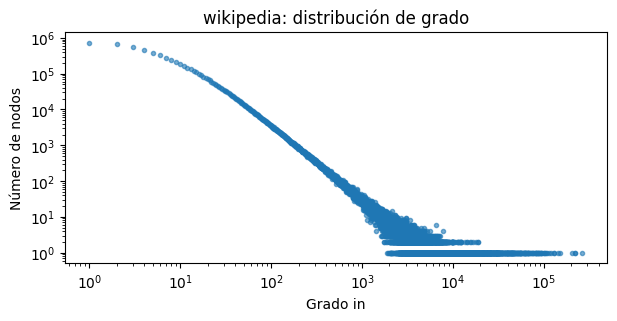

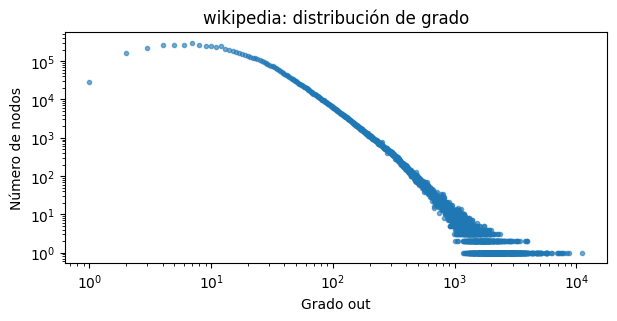

In [10]:
show_dataset('wikipedia')

## 8. Discusión y conclusiones verificables

La correlación de Pearson compara **puntuaciones**, no posiciones ordinales. La coincidencia del top 20 compara conjuntos; un solapamiento alto no implica idéntico orden. Las tablas de cambio de posición muestran el efecto de cada personalización respecto de PageRank uniforme.

La proporción de semillas en el top 20 es una medida descriptiva de afinidad con las reglas utilizadas, **no precisión semántica evaluada con etiquetas independientes**. Debe interpretarse junto con los títulos y ejemplos.

Los tiempos incluyen el trabajo distribuido medido por algoritmo, pero no equivalen al coste completo de descarga, extracción y preparación. Cuando están disponibles, las mediciones de memoria suman RSS del proceso y descendientes al final de cada iteración: pueden contar páginas compartidas varias veces y omitir picos entre muestras. Los experimentos sobre redes distintas no constituyen por sí solos una comparación controlada de escalabilidad.

La siguiente tabla determina qué conclusiones se pueden sostener con las ejecuciones presentes. No se presenta un resultado pendiente como si hubiera sido obtenido.

In [11]:
rows = []
for dataset in ['hepph', 'spotify', 'wikipedia']:
    p = ROOT/'results'/dataset/'complete.json'
    if p.exists():
        obj = json.loads(p.read_text())
        rows.append({'Dataset': dataset, 'Análisis terminado': True,
                     'Tres temas disponibles': obj['all_topics'], 'Todos convergieron': obj['all_converged']})
    else:
        rows.append({'Dataset': dataset, 'Análisis terminado': False,
                     'Tres temas disponibles': False, 'Todos convergieron': None})
status = pd.DataFrame(rows)
display(status)
if status['Análisis terminado'].all() and status['Tres temas disponibles'].all():
    print('Hay resultados de los tres métodos para las tres redes; revisar convergencia y limitaciones antes de concluir.')
else:
    print('ENTREGA EXPERIMENTAL INCOMPLETA: faltan etapas indicadas arriba. No se concluye sobre redes pendientes.')


,Dataset,Análisis terminado,Tres temas disponibles,Todos convergieron
0,hepph,True,True,True
1,spotify,True,True,True
2,wikipedia,True,True,True


Hay resultados de los tres métodos para las tres redes; revisar convergencia y limitaciones antes de concluir.


## 9. Referencias

- [Wikimedia: dump de Wikipedia en inglés](https://dumps.wikimedia.org/enwiki/latest/).
- [SNAP: cit-HepPh, descripción, estadísticas y referencias originales](https://snap.stanford.edu/data/cit-HepPh.html).
- [Julian Freyberg: Spotify Artist Feature Collaboration Network](https://www.kaggle.com/datasets/jfreyberg/spotify-artist-feature-collaboration-network/).
- [arXiv: manual de su API de metadatos](https://info.arxiv.org/help/api/user-manual.html).
- [Apache Spark 3.5.7: RDD, persistencia y operaciones distribuidas](https://spark.apache.org/docs/3.5.7/rdd-programming-guide.html).

Las reglas temáticas son decisiones operativas de este trabajo y deben distinguirse de etiquetas validadas por especialistas.